In [1]:
!pip install numpy pandas plotly

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------- ----------------- 6.0/10.9 MB 49.3 MB/s eta 0:00:01
   -------------------------------- ------- 8.9/10.9 MB 35.4 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 18.8 MB/s  0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.7 MB 41.5 MB/s eta 0:00:01
   ----------- ---------------------------- 2.9/9.7 MB 6.5 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.7 MB 7.6 MB/s eta 0:00:01
   ------------------ --------------------- 4.5/9.7 MB 7.6 MB/s eta 0:00:01
   ------------------ --------------------- 4.5/9.7 MB 7.6 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 7.9 MB/s  0:00:01

   ---------------------------------------- 0/3 [narwhals]
   ---------------------------------------- 0/3 [narwhals]
   ---------------------------------------- 0/3 [narwhal


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install --upgrade numpy pandas plotly nbformat

In [7]:

import numpy as np
import plotly.graph_objects as go
import webbrowser
import os

# ==========================================
# 1. KONFIGURACJA PLANET
# ==========================================

planets = {
    "Merkury": {
        "r": 0.39, "color": "#A9A9A9",
        "size": 6, "period": 0.24
    },
    "Wenus": {
        "r": 0.72, "color": "#FFA500",
        "size": 9, "period": 0.62
    },
    "Ziemia": {
        "r": 1.00, "color": "#00BFFF",
        "size": 10, "period": 1.00
    },
    "Mars": {
        "r": 1.52, "color": "#FF4500",
        "size": 8, "period": 1.88
    },
    "Jowisz": {
        "r": 2.10, "color": "#DAA520",
        "size": 20, "period": 11.86
    },
    "Saturn": {
        "r": 2.65, "color": "#F4D03F",
        "size": 17, "period": 29.46
    },
    "Uran": {
        "r": 3.15, "color": "#40E0D0",
        "size": 13, "period": 84.0
    },
    "Neptun": {
        "r": 3.65, "color": "#4169E1",
        "size": 13, "period": 165.0
    }
}

fig = go.Figure()

# ==========================================
# 2. KOSMICZNE TŁO – GWIAZDY
# ==========================================

np.random.seed(42)

stars = np.random.uniform(-5, 5, (700, 3))

fig.add_trace(go.Scatter3d(
    x=stars[:, 0],
    y=stars[:, 1],
    z=stars[:, 2],
    mode="markers",
    marker=dict(
        size=1.5,
        color="white",
        opacity=0.75
    ),
    name="Gwiazdy",
    hoverinfo="skip"
))

# ==========================================
# 3. SŁOŃCE
# ==========================================

fig.add_trace(go.Scatter3d(
    x=[0],
    y=[0],
    z=[0],
    mode="markers",
    marker=dict(
        size=30,
        color="#FFD700",
        opacity=1,
        line=dict(
            color="#FF8C00",
            width=4
        )
    ),
    name="☀ Słońce",
    hovertemplate="<b>SŁOŃCE</b><extra></extra>"
))

# ==========================================
# 4. ORBITY I PLANETY
# ==========================================

theta = np.linspace(0, 2*np.pi, 300)

for name, data in planets.items():

    radius = data["r"]
    color = data["color"]
    size = data["size"]

    # Orbita planety
    x_orbit = radius * np.cos(theta)
    y_orbit = radius * np.sin(theta)
    z_orbit = np.zeros_like(theta)

    fig.add_trace(go.Scatter3d(
        x=x_orbit,
        y=y_orbit,
        z=z_orbit,
        mode="lines",
        line=dict(
            color=color,
            width=2
        ),
        opacity=0.4,
        name=f"Orbita {name}",
        hoverinfo="skip"
    ))

    # Pozycja planety
    angle = np.random.uniform(0, 2*np.pi)

    x = radius * np.cos(angle)
    y = radius * np.sin(angle)

    fig.add_trace(go.Scatter3d(
        x=[x],
        y=[y],
        z=[0],
        mode="markers+text",
        marker=dict(
            size=size,
            color=color,
            opacity=1,
            line=dict(
                color="white",
                width=1
            )
        ),
        text=[name],
        textposition="top center",
        textfont=dict(
            color="white",
            size=11
        ),
        name=name,
        hovertemplate=(
            f"<b>{name}</b><br>"
            f"Odległość od Słońca: {radius} AU"
            "<extra></extra>"
        )
    ))

    # ======================================
    # 5. PIERŚCIENIE SATURNA
    # ======================================

    if name == "Saturn":

        for ring_radius in [0.28, 0.36, 0.44]:

            ring_x = (
                x + ring_radius * np.cos(theta)
            )

            ring_y = (
                y + ring_radius * np.sin(theta)
            )

            ring_z = np.zeros_like(theta)

            fig.add_trace(go.Scatter3d(
                x=ring_x,
                y=ring_y,
                z=ring_z,
                mode="lines",
                line=dict(
                    color="#F4D03F",
                    width=4
                ),
                opacity=0.65,
                showlegend=False,
                hoverinfo="skip"
            ))

# ==========================================
# 6. DODATKOWE EFEKTY – MGŁAWICA
# ==========================================

nebula = np.random.uniform(-5, 5, (150, 3))

fig.add_trace(go.Scatter3d(
    x=nebula[:, 0],
    y=nebula[:, 1],
    z=nebula[:, 2],
    mode="markers",
    marker=dict(
        size=2,
        color="#9370DB",
        opacity=0.2
    ),
    name="Kosmiczny pył",
    hoverinfo="skip"
))

# ==========================================
# 7. USTAWIENIA WIZUALIZACJI
# ==========================================

fig.update_layout(

    title=dict(
        text="🌌 UKŁAD SŁONECZNY | WIZUALIZACJA 3D",
        x=0.5,
        font=dict(
            size=24,
            color="#FFFFFF"
        )
    ),

    paper_bgcolor="#030712",
    font=dict(
        color="white",
        family="Arial"
    ),

    scene=dict(

        bgcolor="#030712",

        xaxis=dict(
            title="Oś X",
            showbackground=False,
            gridcolor="#263449",
            zerolinecolor="#263449"
        ),

        yaxis=dict(
            title="Oś Y",
            showbackground=False,
            gridcolor="#263449",
            zerolinecolor="#263449"
        ),

        zaxis=dict(
            title="Oś Z",
            showbackground=False,
            gridcolor="#263449",
            zerolinecolor="#263449"
        ),

        aspectmode="cube",

        camera=dict(
            eye=dict(
                x=1.6,
                y=1.6,
                z=1.2
            )
        )
    ),

    legend=dict(
        bgcolor="rgba(10,20,40,0.8)",
        bordercolor="#334155",
        borderwidth=1,
        font=dict(size=10)
    ),

    margin=dict(
        l=0,
        r=0,
        t=70,
        b=0
    ),

    height=850
)

# ==========================================
# 8. ZAPIS I OTWARCIE W PRZEGLĄDARCE
# ==========================================

file_name = "uklad_sloneczny_3D.html"

file_path = os.path.abspath(file_name)

fig.write_html(
    file_path,
    include_plotlyjs=True,
    full_html=True,
    auto_open=False
)

webbrowser.open("file://" + file_path)

print("WIZUALIZACJA GOTOWA!")
print("Plik zapisano w:")
print(file_path)
print("Otwórz plik HTML w przeglądarce.")


WIZUALIZACJA GOTOWA!
Plik zapisano w:
c:\Users\lab812-03.LABORATORIUM\Documents\GitHub\testMK\uklad_sloneczny_3D.html
Otwórz plik HTML w przeglądarce.


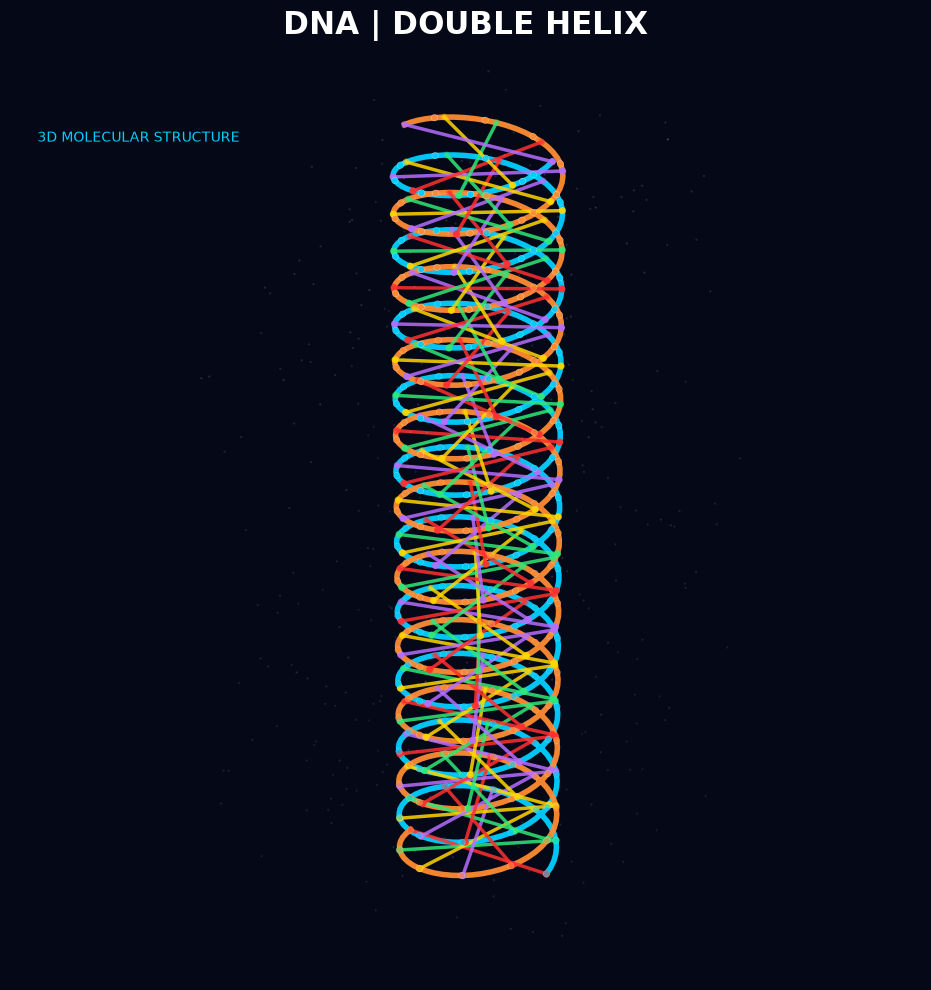

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d import Axes3D

# =========================
# PARAMETRY MODELU DNA
# =========================

np.random.seed(10)

N = 500
turns = 10
height = 20
radius = 2

t = np.linspace(0, 2*np.pi*turns, N)

z = np.linspace(0, height, N)

# Dwie nici DNA
x1 = radius * np.cos(t)
y1 = radius * np.sin(t)

x2 = radius * np.cos(t + np.pi)
y2 = radius * np.sin(t + np.pi)

# Kolory
blue = "#00CFFF"
orange = "#FF8C32"

# =========================
# TWORZENIE FIGURY
# =========================

fig = plt.figure(figsize=(12, 10), facecolor="#050816")

ax = fig.add_subplot(111, projection="3d")
ax.set_facecolor("#050816")

# Pierwsza nić
ax.plot(
    x1, y1, z,
    color=blue,
    linewidth=4,
    alpha=0.95
)

# Druga nić
ax.plot(
    x2, y2, z,
    color=orange,
    linewidth=4,
    alpha=0.95
)

# =========================
# ATOMY NA NICI DNA
# =========================

idx = np.arange(0, N, 5)

ax.scatter(
    x1[idx], y1[idx], z[idx],
    color=blue,
    s=22,
    edgecolors="white",
    linewidths=0.2
)

ax.scatter(
    x2[idx], y2[idx], z[idx],
    color=orange,
    s=22,
    edgecolors="white",
    linewidths=0.2
)

# =========================
# PARY ZASAD AZOTOWYCH
# =========================

pair_t = np.linspace(
    0, 2*np.pi*turns, 100
)

pair_z = np.linspace(0, height, 100)

colors = [
    "#FF3030",  # Adenina
    "#30E879",  # Tymina
    "#FFD700",  # Guanina
    "#B76EFF"   # Cytozyna
]

for i in range(100):

    xx1 = radius * np.cos(pair_t[i])
    yy1 = radius * np.sin(pair_t[i])

    xx2 = radius * np.cos(pair_t[i] + np.pi)
    yy2 = radius * np.sin(pair_t[i] + np.pi)

    color = colors[i % 4]

    # Łącznik między nićmi
    ax.plot(
        [xx1, xx2],
        [yy1, yy2],
        [pair_z[i], pair_z[i]],
        color=color,
        linewidth=2.5,
        alpha=0.85
    )

    # Małe kulki na parach zasad
    ax.scatter(
        [xx1, xx2],
        [yy1, yy2],
        [pair_z[i], pair_z[i]],
        color=color,
        s=18,
        alpha=0.9
    )

# =========================
# DODATKOWE EFEKTY
# =========================

# Gwiazdy w tle
stars = 400

sx = np.random.uniform(-5, 5, stars)
sy = np.random.uniform(-5, 5, stars)
sz = np.random.uniform(0, height, stars)

ax.scatter(
    sx, sy, sz,
    color="white",
    s=0.5,
    alpha=0.35
)

# =========================
# OPIS I WYGLĄD
# =========================

ax.set_title(
    "DNA | DOUBLE HELIX",
    color="white",
    fontsize=22,
    fontweight="bold",
    pad=25
)

ax.text2D(
    0.03, 0.92,
    "3D MOLECULAR STRUCTURE",
    transform=ax.transAxes,
    color="#00CFFF",
    fontsize=10
)

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_zlim(0, height)

ax.set_box_aspect((1, 1, 2.5))
ax.set_axis_off()

# =========================
# ANIMACJA 3D
# =========================

def animate(frame):

    ax.view_init(
        elev=18 + 8*np.sin(frame/100),
        azim=frame
    )

    return []

animation = FuncAnimation(
    fig,
    animate,
    frames=360,
    interval=40,
    blit=False
)

plt.tight_layout()
plt.show()

# Zapis animacji:
# animation.save(
#     "DNA_3D.gif",
#     writer="pillow",
#     fps=25
# )
